# Machine Learning — Sesioni 2

## Multiple Features — modeli më i mirë

**Dataseti:** `employees_enhanced.csv`

**Çka do të bëjmë sot:**
| # | Tema |
|---|------| 
| 1 | `pd.get_dummies()` — teksti → numra | 15' |
| 2 | Feature Engineering — krijimi i veçorive të reja | 20' |
| 3 | Interpretimi i koeficientëve — çka thotë modeli? | 20' |
| 4 | Residuals — ku gabon modeli? | 15' |
| 5 | 5 arsyet pse më shumë ≠ më mirë | 10' |
| 6 | Workshop praktik | 20' |

##  Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('../data/employees_enhanced.csv')
print(f'Shape: {df.shape}')
df.head()


Shape: (100, 11)


,EmployeeID,Emri,Departamenti,Qyteti,Mosha,Rating,Bonus,Data_Punesimit,vite_pune,Paga,churn
0,2001,Genta,Finance,Prishtinë,26,1.0,391,2018-08-07,1.4,2721.80,1
1,2002,Drita,Ops,Durrës,40,5.0,446,2011-05-26,8.6,4473.62,0
2,2003,Hana,Sales,Pejë,25,4.0,236,2017-07-01,2.5,3385.93,0
3,2004,Edon,Marketing,Pejë,56,5.0,68,2007-03-14,12.8,4578.26,0
4,2005,Genta,IT,Prizren,38,1.0,226,2015-04-20,4.7,2845.99,1


##  Modeli A — vetëm Mosha

In [2]:
X_A = df[['Mosha']]
y   = df['Paga']

X_train, X_test, y_train, y_test = train_test_split(
    X_A, y, test_size=0.2, random_state=42)

model_A = LinearRegression().fit(X_train, y_train)
y_pred_A = model_A.predict(X_test)

mse_A  = mean_squared_error(y_test, y_pred_A)
rmse_A = np.sqrt(mse_A)
r2_A   = r2_score(y_test, y_pred_A)

print(f'Model A → R² = {r2_A:.3f}, RMSE = {rmse_A:.0f} €')


Model A → R² = 0.377, RMSE = 449 €


##  Modeli B — më shumë veçori

`Departamenti` është tekst → `pd.get_dummies` e kthen në kolona 0/1

In [3]:
# Provojme te perdorim nje kolone tekst:
# model_test = LinearRegression()
# model_test.fit(df[['Departamenti']], df['Paga'])

### Kur nuk heqim kolonen e enkoduar nga lista e vecorive, atehere kemi problemin Dummy Variable Trap. Kjo quhet multikolinearitet i përsosur dhe e prish modelin.


In [4]:
# provojme drop_first =True dhe False
X_B = pd.get_dummies(
    df[['Mosha', 'Bonus', 'vite_pune', 'Departamenti']],
    drop_first=True)

print(f'Model A: {X_A.shape[1]} kolonë | Model B: {X_B.shape[1]} kolona')
print(list(X_B.columns))
X_B.head()


Model A: 1 kolonë | Model B: 8 kolona
['Mosha', 'Bonus', 'vite_pune', 'Departamenti_HR', 'Departamenti_IT', 'Departamenti_Marketing', 'Departamenti_Ops', 'Departamenti_Sales']


,Mosha,Bonus,vite_pune,Departamenti_HR,Departamenti_IT,Departamenti_Marketing,Departamenti_Ops,Departamenti_Sales
0,26,391,1.4,False,False,False,False,False
1,40,446,8.6,False,False,False,True,False
2,25,236,2.5,False,False,False,False,True
3,56,68,12.8,False,False,True,False,False
4,38,226,4.7,False,True,False,False,False


### CHALLENGE #1
Apliko `pd.get_dummies` në **të gjithë datasetin** — jo vetëm Departamenti. Cilat kolona do të kthehen automatikisht në dummies? Pse?


In [5]:
df_all_dummies = pd.get_dummies(df, drop_first=True, dtype=int)

print(f'Origjinali:  {df.shape[1]} kolona')
print(f'Pas dummies: {df_all_dummies.shape[1]} kolona')
print()
print('Kolonat e reja (të para 10):')
print([c for c in df_all_dummies.columns if c not in df.columns][:10])

Origjinali:  11 kolona
Pas dummies: 95 kolona

Kolonat e reja (të para 10):
['Emri_Besa', 'Emri_Ceni', 'Emri_Drita', 'Emri_Edon', 'Emri_Fatmir', 'Emri_Genta', 'Emri_Hana', 'Emri_Ilir', 'Emri_Jana', 'Departamenti_HR']


### Trajnojmë Modelin B

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_B, y, test_size=0.2, random_state=42)

model_B = LinearRegression().fit(X_train, y_train)
y_pred_B = model_B.predict(X_test)

mse_B  = mean_squared_error(y_test, y_pred_B)
rmse_B = np.sqrt(mse_B)
r2_B   = r2_score(y_test, y_pred_B)

print(f'Model B → R² = {r2_B:.3f}, RMSE = {rmse_B:.0f} €')


Model B → R² = 0.334, RMSE = 465 €


##  Krahasimi — A vs B

In [7]:
comparison = pd.DataFrame({
    'Metrika': ['R² Score', 'MSE (€²)', 'RMSE (€)'],
    'Model A · Mosha': [f'{r2_A:.3f}', f'{mse_A:,.0f}', f'{rmse_A:,.0f}'],
    'Model B · Multiple': [f'{r2_B:.3f}', f'{mse_B:,.0f}', f'{rmse_B:,.0f}'],
    'Përmirësimi': [
        f'+{(r2_B - r2_A) * 100:.1f}pp',
        f'{(mse_B - mse_A) / mse_A * 100:+.1f}%',
        f'{rmse_B - rmse_A:+.0f} €'
    ]
})
comparison


,Metrika,Model A · Mosha,Model B · Multiple,Përmirësimi
0,R² Score,0.377,0.334,+-4.3pp
1,MSE (€²),"201,884","215,973",+7.0%
2,RMSE (€),449,465,+15 €


---
## Feature Engineering — krijimi i veçorive të mençura

**Feature engineering** = ndërtimi i kolonave të reja nga ato ekzistuese, që i japin modelit informacion që s'e sheh drejtpërdrejt.

**Analogji:** të dhënat i japin modelit ingredientët; feature engineering i jep **recetën**.

In [8]:
# Krijojmë 3 veçori të reja "të mençura"
df_fe = df.copy()

# 1) Bonus për vit pune → sa bonus fiton për çdo vit që ka punuar
df_fe['Bonus_per_year'] = df_fe['Bonus'] / df_fe['vite_pune'].replace(0, 0.5)

# 2) Age bucket → grup-mosha (kategorike nga numerike)
df_fe['Age_bucket'] = pd.cut(
    df_fe['Mosha'],
    bins=[0, 30, 45, 100],
    labels=['I ri', 'Mesatar', 'Senior']
)

# 3) Senior flag → 1 nëse ka >5 vite pune
df_fe['Is_Senior'] = (df_fe['vite_pune'] > 5).astype(int)

df_fe[['Mosha', 'vite_pune', 'Bonus', 'Bonus_per_year', 'Age_bucket', 'Is_Senior']].head(8)

,Mosha,vite_pune,Bonus,Bonus_per_year,Age_bucket,Is_Senior
0,26,1.4,391,279.285714,I ri,0
1,40,8.6,446,51.860465,Mesatar,1
2,25,2.5,236,94.400000,I ri,0
3,56,12.8,68,5.312500,Senior,1
4,38,4.7,226,48.085106,Mesatar,0
5,49,8.6,149,17.325581,Senior,1
6,51,8.9,445,50.000000,Senior,1
7,50,11.8,494,41.864407,Senior,1


In [9]:
# Ndërtojmë modelin ME feature engineering
X_fe = pd.get_dummies(
    df_fe[['Mosha', 'Bonus', 'vite_pune', 'Departamenti',
           'Bonus_per_year', 'Age_bucket', 'Is_Senior']],
    drop_first=True,
    dtype=int
)
y = df_fe['Paga']

X_train, X_test, y_train, y_test = train_test_split(X_fe, y, test_size=0.2, random_state=42)

model_fe = LinearRegression()
model_fe.fit(X_train, y_train)
y_pred_fe = model_fe.predict(X_test)

r2_fe = r2_score(y_test, y_pred_fe)
rmse_fe = np.sqrt(mean_squared_error(y_test, y_pred_fe))

print(f'📊 Model me Feature Engineering:')
print(f'   R²   = {r2_fe:.3f}')
print(f'   RMSE = {rmse_fe:.0f} €')
print(f'   Veçori totale: {X_fe.shape[1]}')

📊 Model me Feature Engineering:
   R²   = 0.381
   RMSE = 448 €
   Veçori totale: 12


---
## Interpretimi i koeficientëve — çka thotë modeli?

Linear regression jep formulën:

```
Paga = intercept + β₁·Mosha + β₂·Bonus + β₃·vite_pune + ... 
```

Çdo **koeficient (β)** ka kuptim biznesi konkret:

> **β_Mosha = 25 €** → *Nëse Mosha rritet me 1 vit (dhe çdo veçori tjetër mbetet e njëjtë), Paga rritet me 25 €.*

Kjo është fuqia më e madhe e Linear Regression: **explainability**.

In [10]:
# Ndërtojmë një tabelë të lexueshme të koeficientëve
coefs = pd.DataFrame({
    'Veçori':      X_fe.columns,
    'Koeficient':  model_fe.coef_,
    'Impakt_€':    model_fe.coef_.round(1)
})

# Sortojmë sipas madhësisë absolute
coefs['abs'] = coefs['Koeficient'].abs()
coefs = coefs.sort_values('abs', ascending=False).drop(columns='abs').reset_index(drop=True)

print(f'📌 Intercept (paga bazë, kur çdo veçori = 0): {model_fe.intercept_:.0f} €')
print()
print('Top koeficientët (sipas fuqisë absolute):')
coefs.head(10)

📌 Intercept (paga bazë, kur çdo veçori = 0): 2226 €

Top koeficientët (sipas fuqisë absolute):


,Veçori,Koeficient,Impakt_€
0,Departamenti_Ops,249.408208,249.4
1,Departamenti_Marketing,165.415649,165.4
2,Is_Senior,140.243101,140.2
3,Age_bucket_Mesatar,-110.402875,-110.4
4,vite_pune,60.857233,60.9
5,Age_bucket_Senior,-56.019576,-56.0
6,Departamenti_HR,-27.313670,-27.3
7,Departamenti_Sales,12.513800,12.5
8,Mosha,12.029876,12.0
9,Departamenti_IT,2.201982,2.2


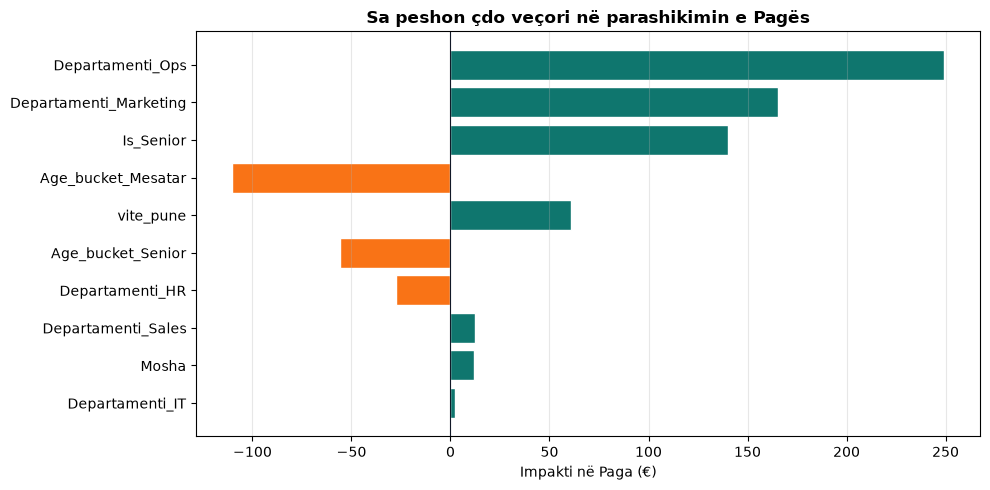

In [11]:
# Vizualizim si bar plot — pozitiv teal, negativ orange
top = coefs.head(10).iloc[::-1]
colors = ['#0F766E' if v > 0 else '#F97316' for v in top['Koeficient']]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top['Veçori'], top['Koeficient'], color=colors, edgecolor='white')
ax.axvline(0, color='#111827', linewidth=0.8)
ax.set_xlabel('Impakti në Paga (€)')
ax.set_title('Sa peshon çdo veçori në parashikimin e Pagës', fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

---
## Residuals — ku gabon modeli?

**Residual** = `Paga_reale − Paga_e_parashikuar`. Çdo pikë në test set ka një residual.

**Interpretimi:**
- Residual **pozitiv** → modeli e **nënvlerësoi** pagën (personi paguhet më shumë nga sa parashikoi).
- Residual **negativ** → modeli e **mbivlerësoi** pagën.
- Ideal: residuals shpërndarë rreth 0, pa pattern.

Nëse shohim një **pattern** — modeli po humb diçka sistematike.

In [12]:
residuals = y_test - y_pred_fe

print(f'📉 Statistika e residuals:')
print(f'   Mesatarja  : {residuals.mean():+.1f} €  (ideal ≈ 0)')
print(f'   Std        : {residuals.std():.0f} €')
print(f'   Min        : {residuals.min():.0f} €  (mbivlerësimi më i madh)')
print(f'   Max        : {residuals.max():.0f} €  (nënvlerësimi më i madh)')

📉 Statistika e residuals:
   Mesatarja  : -21.7 €  (ideal ≈ 0)
   Std        : 459 €
   Min        : -712 €  (mbivlerësimi më i madh)
   Max        : 879 €  (nënvlerësimi më i madh)


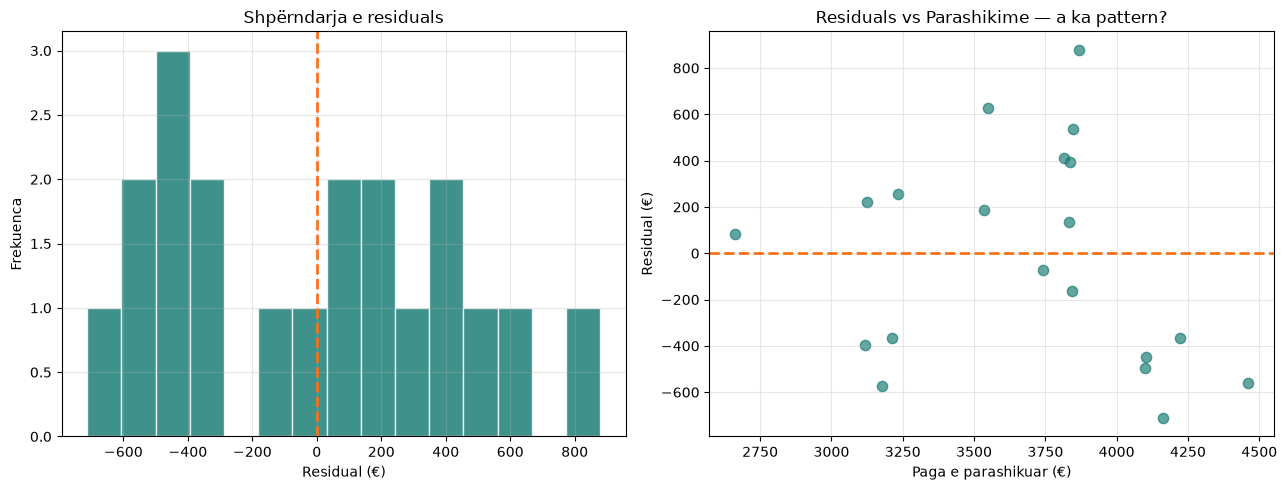

In [13]:
# 2 grafikë krah për krah: shpërndarja + residuals vs parashikime
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Shpërndarja e residuals
axes[0].hist(residuals, bins=15, color='#0F766E', alpha=0.8, edgecolor='white')
axes[0].axvline(0, color='#F97316', linewidth=2, linestyle='--')
axes[0].set_xlabel('Residual (€)')
axes[0].set_ylabel('Frekuenca')
axes[0].set_title('Shpërndarja e residuals')
axes[0].grid(alpha=0.3)

# Residuals vs parashikime
axes[1].scatter(y_pred_fe, residuals, alpha=0.65, color='#0F766E', s=55)
axes[1].axhline(0, color='#F97316', linewidth=2, linestyle='--')
axes[1].set_xlabel('Paga e parashikuar (€)')
axes[1].set_ylabel('Residual (€)')
axes[1].set_title('Residuals vs Parashikime — a ka pattern?')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Ushtrimi 1 — Shtoni **Qyteti**

1. Shtoni veçorinë **Qyteti** në model.
2. Llogaritni **R²** dhe **residuals**.
3. Vizualizoni grafikun **Residuals vs Parashikime**.
4. A u përmirësua modeli? A shihni ndonjë pattern te residuals?


### Ushtrimi 2 — Hiqni **Bonus**

1. Hiqni veçorinë **Bonus** nga modeli.
2. Llogaritni **R²** dhe **residuals**.
3. Vizualizoni grafikun **Residuals vs Parashikime**.
4. Si ndryshoi modeli? A shihni ndonjë pattern te residuals?